# Pillar shape vs bonding (MEA1K24, test17)

Does the shape of an electrode's gold pillar predict whether it bonded to the polyimide pad above it?

- **Pads → electrodes:** `pad2el_mapping.csv` from the manual flex alignment. It lists every MEA1K electrode under
  each of the 768 pads (4–9 per pad).
- **Bonding:** test17 impedance sweep. The pads carry a low load, so a bonded electrode reads a few kΩ and an open
  one about 170 kΩ (same as the negative controls). Every electrode under a pad falls into one of three groups:
  - **bonded:** measured, low impedance
  - **open:** measured, high impedance (includes the negative controls that lie under a pad)
  - **not measured:** under a pad, but not connected in the preceding connectivity scan, so never measured
- **Pillars:** profilometer scan of the same chip (2026-10-30), from `surface_profiling/analyze_mea_cells.py`
  (`mea_cell_quality.csv`) and `mea_grid.py` (`*_mea_cells.npz`, a 25×25 height crop per electrode). Heights are µm
  above the trench floor. Only pillars that passed the profiling quality check are used.

Caveats:
- Height varies a lot between stitching fields (scan artefact plus real variation), so raw height partly encodes
  position on the chip. Two position-free measures are used as well: height relative to the neighbouring pillars,
  and height relative to the other pillars **under the same pad**. The within-pad comparison is the cleanest test.
- The scan predates test17. Tests 13 and 15 were bonded on this chip in between.

In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
DEV_DIR  = '/Volumes/large/BMI/VirtualReality/SpatialSequenceLearning/devices'
REC_DIR  = os.path.join(DEV_DIR, 'headstage_devices/MEA1K24/recordings/2026-11-11_15.10_test17_100_36umP_PT5_Imp/processed')
IMP_CSV  = os.path.join(REC_DIR, 'all_impedance.csv')
MAP_CSV  = os.path.join(REC_DIR, 'pad2el_mapping.csv')
PROF_DIR = os.path.join(DEV_DIR, 'surface_profiles')
QUAL_CSV = os.path.join(PROF_DIR, 'mea_cell_analysis/mea_cell_quality.csv')     # analyze_mea_cells.py output
CROPS    = os.path.join(PROF_DIR, '2026-10-30_profilometer/exported/MEA1K_24_mea_cells.npz')
CHIP     = 'MEA1K_24'                       # chip label in mea_cell_quality.csv

BOND_MAX_OHM = 20_000       # bonded when the electrode reads below this (clusters: ~4 kΩ vs ~170 kΩ)
NEIGH        = 7            # neighbourhood half-width (cells) for the relative height

N_COLS, N_ROWS = 220, 120
GROUPS = {'bonded': '#2e8b57', 'open': '#d6336c', 'not measured': '0.55'}

## Bonding: impedance per electrode

1838 electrodes measured, 160 negative controls


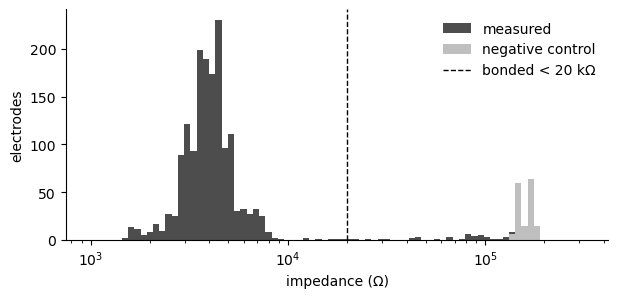

In [4]:
imp = pd.read_csv(IMP_CSV).set_index('electrode')
print(f"{len(imp)} electrodes measured, {imp.negative_ctrl.sum()} negative controls")

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(3, 5.5, 80)
ax.hist(imp.loc[~imp.negative_ctrl, 'impedance_Ohm'], bins=bins, color='0.3', label='measured')
ax.hist(imp.loc[imp.negative_ctrl, 'impedance_Ohm'], bins=bins, color='0.75', label='negative control')
ax.axvline(BOND_MAX_OHM, color='k', ls='--', lw=1, label=f'bonded < {BOND_MAX_OHM/1e3:.0f} kΩ')
ax.set_xscale('log'); ax.set_xlabel('impedance (Ω)'); ax.set_ylabel('electrodes')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
plt.show()

## Electrodes under a pad: three groups

In [5]:
pad2el = pd.read_csv(MAP_CSV).astype({'pad_id': int, 'mea1k_el': int})
el = pad2el[['pad_id', 'mea1k_el', 'pad_x_aligned', 'pad_y_aligned']].copy()
z = imp['impedance_Ohm'].reindex(el['mea1k_el']).to_numpy()
el['impedance_Ohm'] = z
el['group'] = np.select([np.isnan(z), z < BOND_MAX_OHM], ['not measured', 'bonded'], 'open')
print(f"{el.pad_id.nunique()} pads, {len(el)} electrodes under a pad")
print(el.group.value_counts().to_string())

outside = imp.loc[~imp.index.isin(el['mea1k_el']) & ~imp.negative_ctrl, 'impedance_Ohm']
print(f"\nmeasured but under no pad (alignment margin): {len(outside)}, of which {(outside < BOND_MAX_OHM).sum()} bonded")

768 pads, 5878 electrodes under a pad
group
not measured    4196
bonded          1566
open             116

measured but under no pad (alignment margin): 26, of which 24 bonded


In [6]:
qual = pd.read_csv(QUAL_CSV)
qual = qual[qual.chip == CHIP].set_index('el').sort_index()
npz = np.load(CROPS)
crops, dx = npz['crops'].astype(np.float32), float(npz['dx_um'])   # crops: (26400, 25, 25), axis 1 = x, axis 2 = y

H     = qual['h_top_um'].where(qual['status_name'] == 'included').to_numpy().reshape(N_ROWS, N_COLS)
FIELD = qual['field'].to_numpy().reshape(N_ROWS, N_COLS)

def neigh_median(e):
    """Median pillar top of the included pillars within ±NEIGH cells in the same stitching field."""
    r, c = divmod(int(e), N_COLS)
    sl = np.s_[max(r - NEIGH, 0):r + NEIGH + 1, max(c - NEIGH, 0):c + NEIGH + 1]
    return np.nanmedian(np.where(FIELD[sl] == FIELD[r, c], H[sl], np.nan))

def add_pillars(el):
    d = el.assign(el_scan=el['mea1k_el']).join(qual, on='el_scan')
    d = d[d.status_name == 'included'].copy()
    d['h_rel_um'] = d['h_top_um'] - d['el_scan'].map(neigh_median)
    d['h_pad_um'] = d['h_top_um'] - d.groupby('pad_id')['h_top_um'].transform('mean')
    d.loc[d.groupby('pad_id')['h_top_um'].transform('size') < 2, 'h_pad_um'] = np.nan
    return d

use = add_pillars(el)
print(f"pillars passing the quality check: {len(use)} of {len(el)}")
print(use.group.value_counts().to_string())

pillars passing the quality check: 4769 of 5878
group
not measured    3447
bonded          1235
open              87


Where the groups sit on the pillar height map .

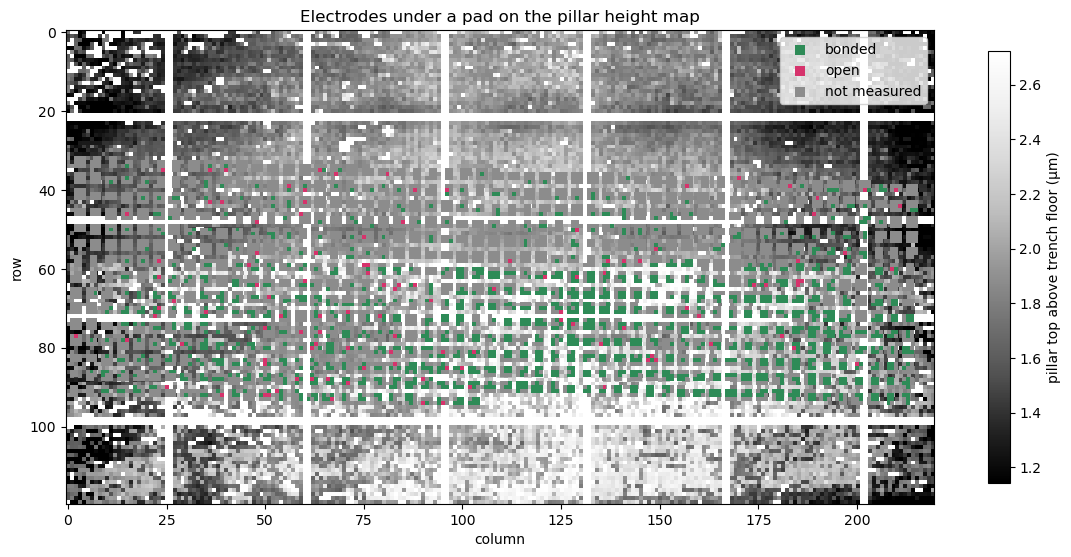

In [7]:
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(H, cmap='Greys_r', vmin=np.nanpercentile(H, 2), vmax=np.nanpercentile(H, 98))
r, c = np.divmod(el['mea1k_el'].to_numpy(), N_COLS)
for g, col in GROUPS.items():
    s = (el['group'] == g).to_numpy()
    ax.scatter(c[s], r[s], s=5, color=col, marker='s', lw=0, label=g)
ax.set_xlabel('column'); ax.set_ylabel('row')
ax.legend(loc='upper right', frameon=True, markerscale=3)
fig.colorbar(im, ax=ax, shrink=0.7, label='pillar top above trench floor (µm)')
ax.set_title('Electrodes under a pad on the pillar height map')
plt.show()

## Electrode-wise: pillar features per group

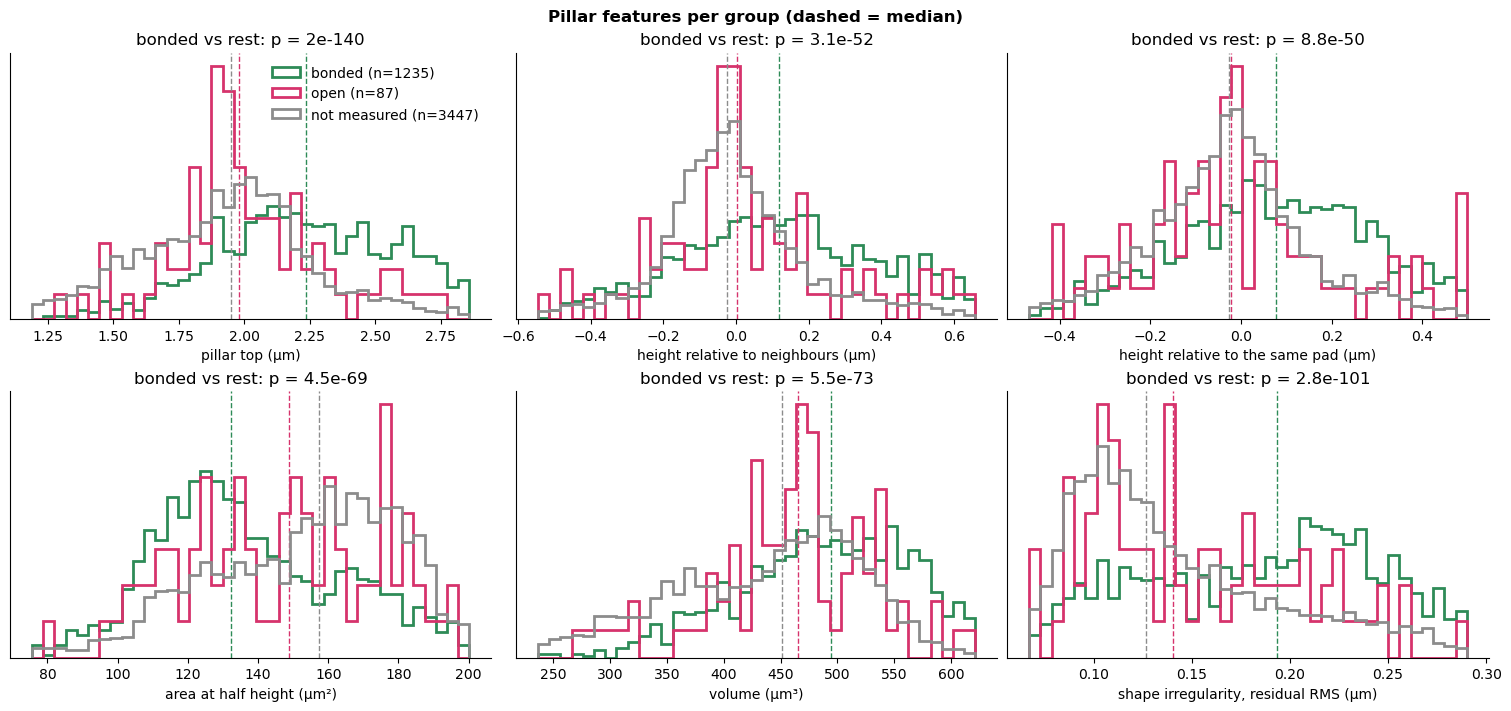

,bonded,open,not measured,p_bonded_vs_rest
feature,,,,
h_top_um,2.235,1.981,1.949,2.0e-140
h_rel_um,0.117,0.003,-0.024,3.1e-52
h_pad_um,0.076,-0.021,-0.027,8.8e-50
area_halfmax_um2,132.351,148.714,157.377,4.5e-69
volume_um3,494.182,465.646,451.645,5.5e-73
shape_rms_um,0.193,0.140,0.127,2.8e-101


In [8]:
FEATURES = [('h_top_um',         'pillar top (µm)'),
            ('h_rel_um',         'height relative to neighbours (µm)'),
            ('h_pad_um',         'height relative to the same pad (µm)'),
            ('area_halfmax_um2', 'area at half height (µm²)'),
            ('volume_um3',       'volume (µm³)'),
            ('shape_rms_um',     'shape irregularity, residual RMS (µm)')]

rows = []
fig, axs = plt.subplots(2, 3, figsize=(15, 7), layout='constrained')
for ax, (f, lbl) in zip(axs.flat, FEATURES):
    bins = np.linspace(*np.nanpercentile(use[f], [1, 99]), 40)
    v = {g: use.loc[use.group == g, f].dropna() for g in GROUPS}
    for g, col in GROUPS.items():
        ax.hist(v[g], bins=bins, density=True, histtype='step', lw=2, color=col, label=f'{g} (n={len(v[g])})')
        ax.axvline(v[g].median(), color=col, ls='--', lw=1)
    nb = pd.concat([v['open'], v['not measured']])
    p = stats.mannwhitneyu(v['bonded'], nb).pvalue
    ax.set_xlabel(lbl); ax.set_title(f'bonded vs rest: p = {p:.2g}')
    ax.spines[['top', 'right']].set_visible(False); ax.set_yticks([])
    rows.append(dict(feature=f, **{g: v[g].median() for g in GROUPS}, p_bonded_vs_rest=p))
axs.flat[0].legend(frameon=False)
fig.suptitle('Pillar features per group (dashed = median)', fontweight='bold')
plt.show()

summary = pd.DataFrame(rows).set_index('feature')
summary.style.format('{:.3f}').format('{:.1e}', subset='p_bonded_vs_rest')

Share of bonded electrodes by pillar height, in quintiles of each height measure (95 % Wilson intervals).

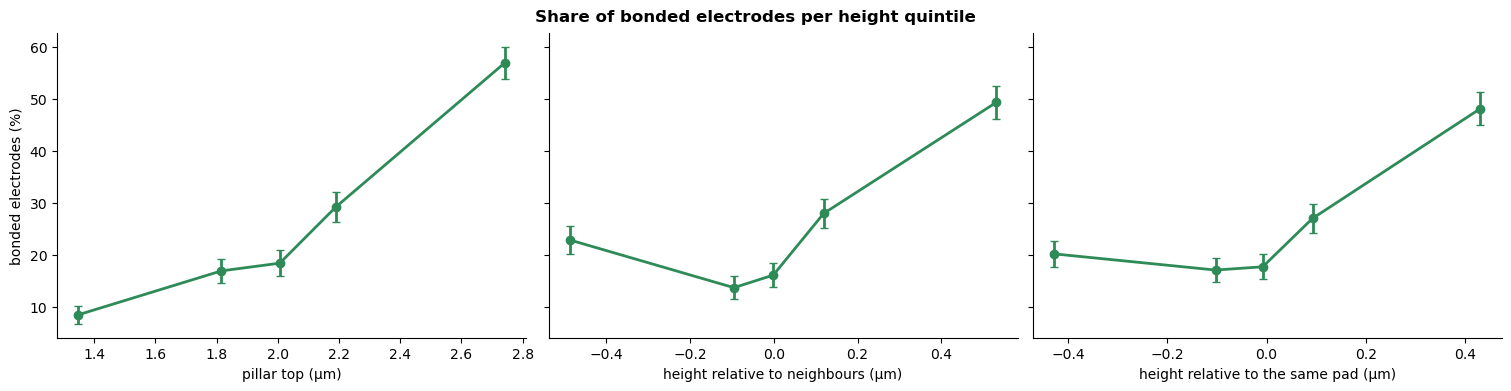

In [9]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return c, c - h, c + h

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), layout='constrained', sharey=True)
for ax, (f, lbl) in zip(axs, FEATURES[:3]):
    d = use.dropna(subset=[f])
    g = d.groupby(pd.qcut(d[f], 5), observed=True)['group'].agg(n='size', k=lambda s: (s == 'bonded').sum())
    m, lo, hi = wilson(g.k.to_numpy(), g.n.to_numpy())
    ax.errorbar([iv.mid for iv in g.index], m * 100, yerr=[(m - lo) * 100, (hi - m) * 100],
                color=GROUPS['bonded'], marker='o', capsize=3, lw=2)
    ax.set_xlabel(lbl); ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('bonded electrodes (%)')
fig.suptitle('Share of bonded electrodes per height quintile', fontweight='bold')
plt.show()

Median x / y profile through the bump peak (as in `analyze_mea_cells.py`), band = middle 50 %.

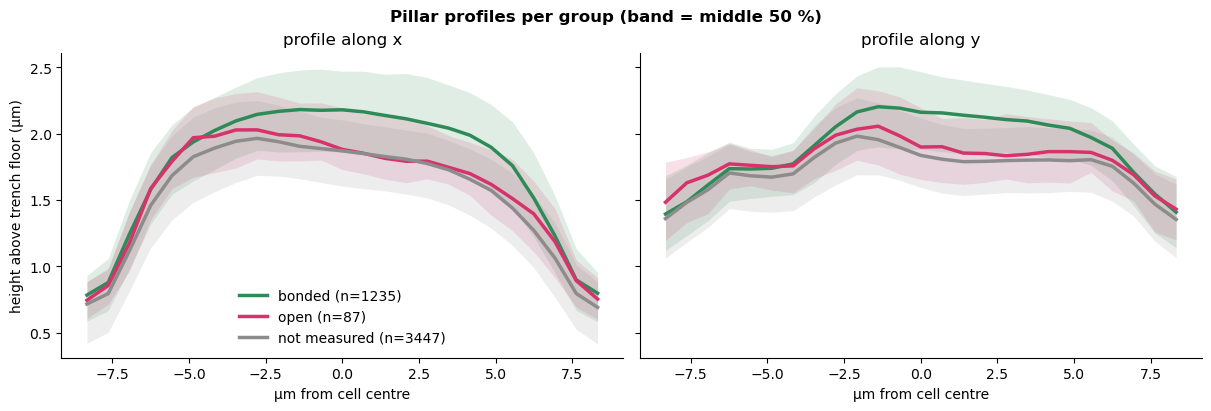

In [10]:
n = crops.shape[1]
o = (np.arange(n) - (n - 1) / 2) * dx
C = crops[use['el_scan'].to_numpy()]
p50 = np.median(C, 0)
by, bx = np.argmax(p50.max(0)), np.argmax(p50.max(1))      # peak row / column of the median bump
profiles = {'x': C[:, :, by - 1:by + 2].mean(2), 'y': C[:, bx - 1:bx + 2, :].mean(1)}

fig, axs = plt.subplots(1, 2, figsize=(12, 4), layout='constrained', sharey=True)
for ax, (axis, P) in zip(axs, profiles.items()):
    for g, col in GROUPS.items():
        sel = (use.group == g).to_numpy()
        q1, q2, q3 = np.percentile(P[sel], [25, 50, 75], axis=0)
        ax.fill_between(o, q1, q3, color=col, alpha=0.15, lw=0)
        ax.plot(o, q2, color=col, lw=2.5, label=f'{g} (n={sel.sum()})')
    ax.set_title(f'profile along {axis}'); ax.set_xlabel('µm from cell centre')
    ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('height above trench floor (µm)'); axs[0].legend(frameon=False)
fig.suptitle('Pillar profiles per group (band = middle 50 %)', fontweight='bold')
plt.show()

## Pad-wise

Per pad: how many of its electrodes bonded, and what its pillars look like. The pad map uses the aligned pad
coordinates (MEA1K frame, µm).

71% of pads have at least one bonded electrode


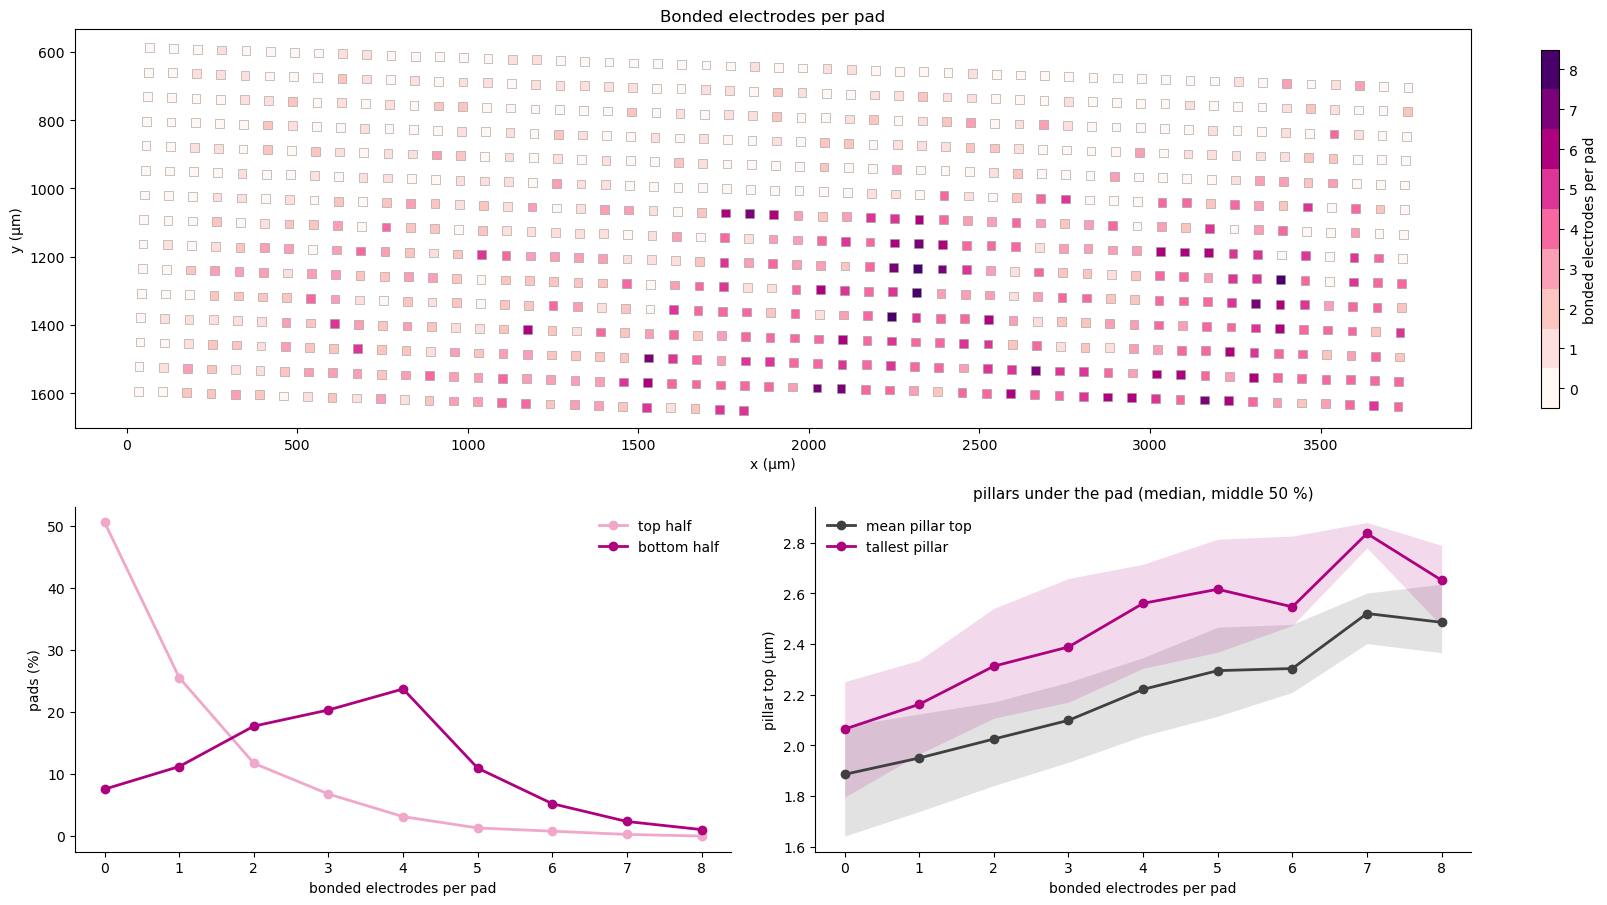

In [11]:
pads = el.groupby('pad_id').agg(x=('pad_x_aligned', 'first'), y=('pad_y_aligned', 'first'),
                                n_el=('mea1k_el', 'size'), n_bonded=('group', lambda s: (s == 'bonded').sum()))
pp = use.groupby('pad_id').agg(h_mean=('h_top_um', 'mean'), h_max=('h_top_um', 'max'),
                               h_rel_mean=('h_rel_um', 'mean'), n_ok=('h_top_um', 'size'))
pads = pads.join(pp)
pads['half'] = np.where(pads.y < pads.y.median(), 'top half', 'bottom half')
print(f"{(pads.n_bonded > 0).mean():.0%} of pads have at least one bonded electrode")

fig = plt.figure(figsize=(16, 9), layout='constrained')
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])

ax = fig.add_subplot(gs[0, :])
cmap = plt.get_cmap('RdPu', pads.n_bonded.max() + 1)
sc = ax.scatter(pads.x, pads.y, c=pads.n_bonded, cmap=cmap, vmin=-0.5, vmax=pads.n_bonded.max() + 0.5,
                marker='s', s=40, edgecolors='0.6', linewidths=0.4)
ax.set_aspect('equal'); ax.invert_yaxis(); ax.set_xlabel('x (µm)'); ax.set_ylabel('y (µm)')
fig.colorbar(sc, ax=ax, label='bonded electrodes per pad', ticks=range(pads.n_bonded.max() + 1), shrink=0.8)
ax.set_title('Bonded electrodes per pad')

ax = fig.add_subplot(gs[1, 0])
k = np.arange(pads.n_bonded.max() + 1)
for half, col in (('top half', '#f1a7c9'), ('bottom half', '#ae017e')):
    cnt = pads.loc[pads.half == half, 'n_bonded'].value_counts().reindex(k, fill_value=0)
    ax.plot(k, cnt / cnt.sum() * 100, marker='o', lw=2, color=col, label=half)
ax.set_xlabel('bonded electrodes per pad'); ax.set_ylabel('pads (%)'); ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)

ax = fig.add_subplot(gs[1, 1])
for f, lbl, col in (('h_mean', 'mean pillar top', '0.25'), ('h_max', 'tallest pillar', '#ae017e')):
    g = pads.dropna(subset=[f]).groupby('n_bonded')[f]
    q = g.quantile([.25, .5, .75]).unstack()
    ax.fill_between(q.index, q[.25], q[.75], color=col, alpha=0.15, lw=0)
    ax.plot(q.index, q[.5], marker='o', lw=2, color=col, label=lbl)
ax.set_xlabel('bonded electrodes per pad'); ax.set_ylabel('pillar top (µm)'); ax.legend(frameon=False)
ax.set_title('pillars under the pad (median, middle 50 %)', fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

**Within a pad.** In pads where some electrodes bonded and some did not, compare the bonded pillars with their
unbonded neighbours under the same pad. Both share one pad, one contact pressure and (almost always) one stitching
field, so position effects cancel.

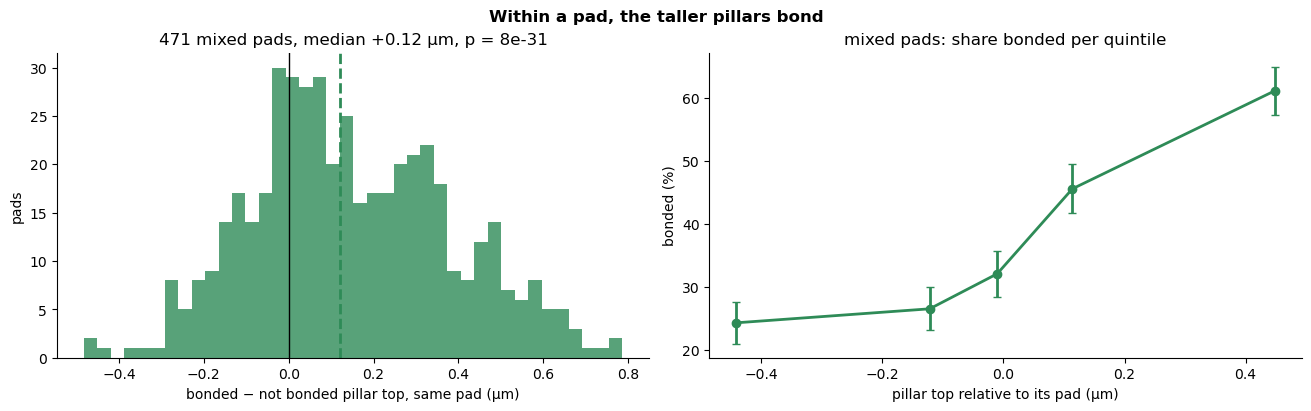

pads with exactly one bonded electrode: 140; the bonded one is the tallest in 25% (chance 17%)


In [12]:
def within_pad(d):
    """Per mixed pad: mean pillar top of bonded minus not-bonded electrodes."""
    m = d.assign(b=d.group == 'bonded').groupby(['pad_id', 'b'])['h_top_um'].mean().unstack()
    return (m[True] - m[False]).dropna()

diff = within_pad(use)
p = stats.wilcoxon(diff).pvalue

# single-bonded pads: is the bonded pillar the tallest one under the pad?
single = [x for _, x in use.groupby('pad_id') if (x.group == 'bonded').sum() == 1 and len(x) >= 3]
tallest = np.mean([x.loc[x.group == 'bonded', 'h_top_um'].iloc[0] == x.h_top_um.max() for x in single])
chance = np.mean([1 / len(x) for x in single])

fig, axs = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
ax = axs[0]
ax.hist(diff, bins=40, color=GROUPS['bonded'], alpha=0.8)
ax.axvline(0, color='k', lw=1); ax.axvline(diff.median(), color=GROUPS['bonded'], ls='--', lw=2)
ax.set_xlabel('bonded − not bonded pillar top, same pad (µm)'); ax.set_ylabel('pads')
ax.set_title(f'{len(diff)} mixed pads, median {diff.median():+.2f} µm, p = {p:.1g}')
ax.spines[['top', 'right']].set_visible(False)

ax = axs[1]
d = use.dropna(subset=['h_pad_um'])
d = d[d.groupby('pad_id')['group'].transform(lambda s: (s == 'bonded').any() and (s != 'bonded').any())]
g = d.groupby(pd.qcut(d['h_pad_um'], 5), observed=True)['group'].agg(n='size', k=lambda s: (s == 'bonded').sum())
m, lo, hi = wilson(g.k.to_numpy(), g.n.to_numpy())
ax.errorbar([iv.mid for iv in g.index], m * 100, yerr=[(m - lo) * 100, (hi - m) * 100],
            color=GROUPS['bonded'], marker='o', capsize=3, lw=2)
ax.set_xlabel('pillar top relative to its pad (µm)'); ax.set_ylabel('bonded (%)')
ax.set_title('mixed pads: share bonded per quintile')
ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Within a pad, the taller pillars bond', fontweight='bold')
plt.show()
print(f"pads with exactly one bonded electrode: {len(single)}; the bonded one is the tallest in {tallest:.0%} "
      f"(chance {chance:.0%})")